In [126]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings

warnings.filterwarnings('ignore')

In [127]:
import os

os.chdir(
    r"C:\Users\Prakhar Gade\Desktop\Predictive Customer Main\notebooks"
)

In [128]:
df = pd.read_csv(
    '../dataset/WA_Fn-UseC_-Telco-Customer-Churn.csv'
)

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [129]:
df.shape

(7043, 21)

In [130]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [131]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [132]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [133]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [134]:
(df == ' ').sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [135]:
df.duplicated().sum()

np.int64(0)

In [136]:
df['customerID'].duplicated().sum()

np.int64(0)

In [137]:
df['Churn'].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [138]:
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'],
    errors='coerce'
)

In [139]:
df['TotalCharges'].dtype

dtype('float64')

In [140]:
df['TotalCharges'].isnull().sum()

np.int64(11)

In [141]:
df[df['TotalCharges'].isnull()][
    ['tenure', 'MonthlyCharges', 'TotalCharges']
]

,tenure,MonthlyCharges,TotalCharges
488,0,52.55,NaN
753,0,20.25,NaN
936,0,80.85,NaN
1082,0,25.75,NaN
1340,0,56.05,NaN
3331,0,19.85,NaN
3826,0,25.35,NaN
4380,0,20.00,NaN
5218,0,19.70,NaN
6670,0,73.35,NaN


In [142]:
print("Numerical Columns:")

print(
    df.select_dtypes(include=np.number).columns
)

print("\nCategorical Columns:")

print(
    df.select_dtypes(include='object').columns
)

Numerical Columns:
Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='object')

Categorical Columns:
Index(['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService',
       'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
       'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
       'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn'],
      dtype='object')


## 4. Exploratory Data Analysis

### 4.1 Customer Churn Distribution

This visualization shows the distribution of
customers who stayed and customers who left.

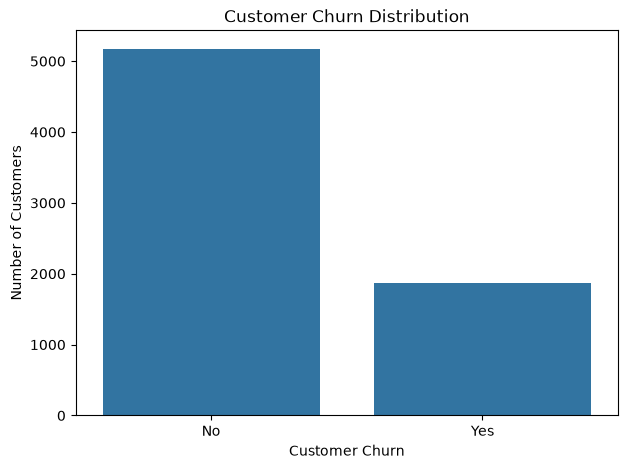

In [143]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='Churn'
)

plt.title('Customer Churn Distribution')

plt.xlabel('Customer Churn')

plt.ylabel('Number of Customers')

plt.show()

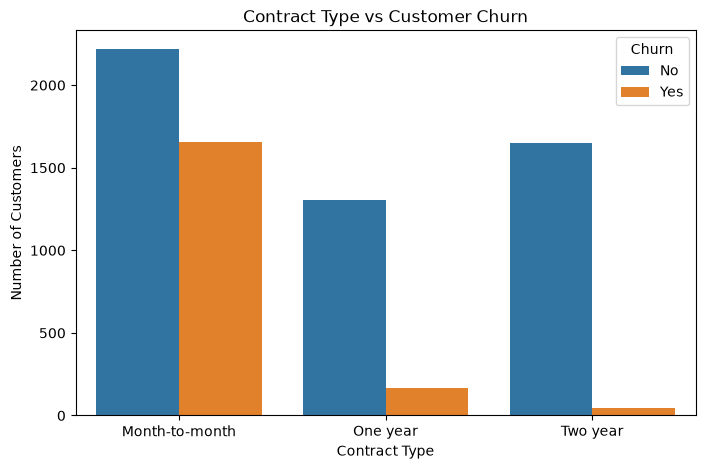

In [144]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='Contract',
    hue='Churn'
)

plt.title('Contract Type vs Customer Churn')

plt.xlabel('Contract Type')

plt.ylabel('Number of Customers')

plt.show()

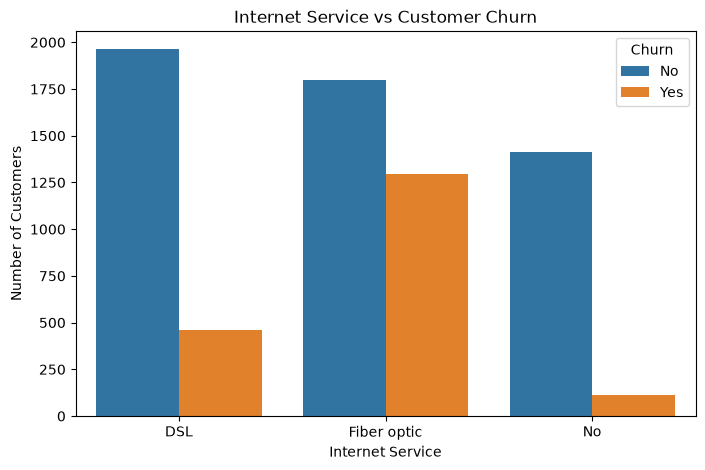

In [145]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='InternetService',
    hue='Churn'
)

plt.title('Internet Service vs Customer Churn')

plt.xlabel('Internet Service')

plt.ylabel('Number of Customers')

plt.show()

In [146]:
contract_churn = pd.crosstab(
    df['Contract'],
    df['Churn'],
    normalize='index'
) * 100

print(contract_churn)

Churn                  No        Yes
Contract                            
Month-to-month  57.290323  42.709677
One year        88.730482  11.269518
Two year        97.168142   2.831858


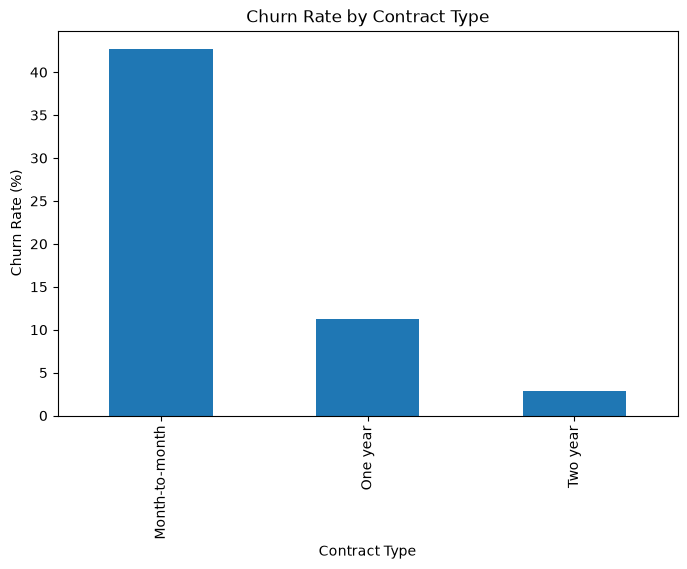

In [147]:
contract_churn['Yes'].plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Churn Rate by Contract Type')

plt.xlabel('Contract Type')

plt.ylabel('Churn Rate (%)')

plt.show()

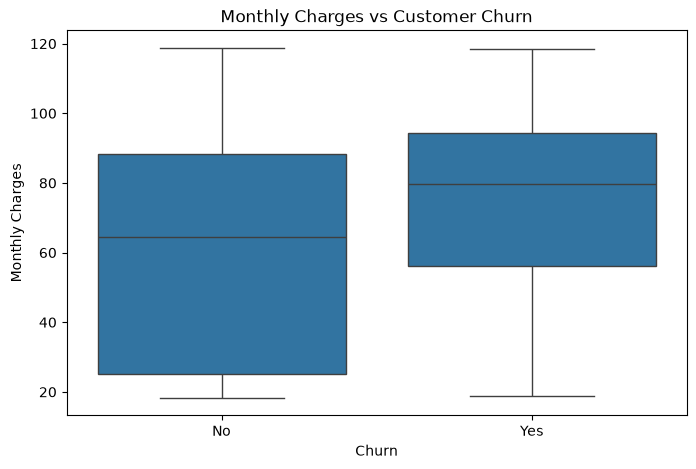

In [148]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='Churn',
    y='MonthlyCharges'
)

plt.title('Monthly Charges vs Customer Churn')

plt.xlabel('Churn')

plt.ylabel('Monthly Charges')

plt.show()

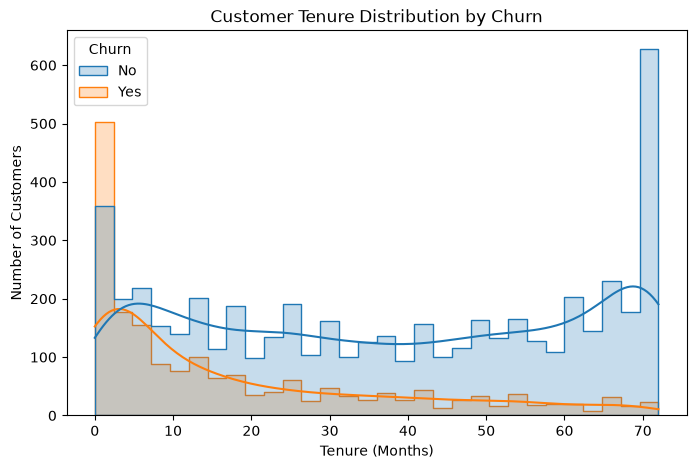

In [149]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x='tenure',
    hue='Churn',
    bins=30,
    kde=True,
    element='step'
)

plt.title('Customer Tenure Distribution by Churn')

plt.xlabel('Tenure (Months)')

plt.ylabel('Number of Customers')

plt.show()

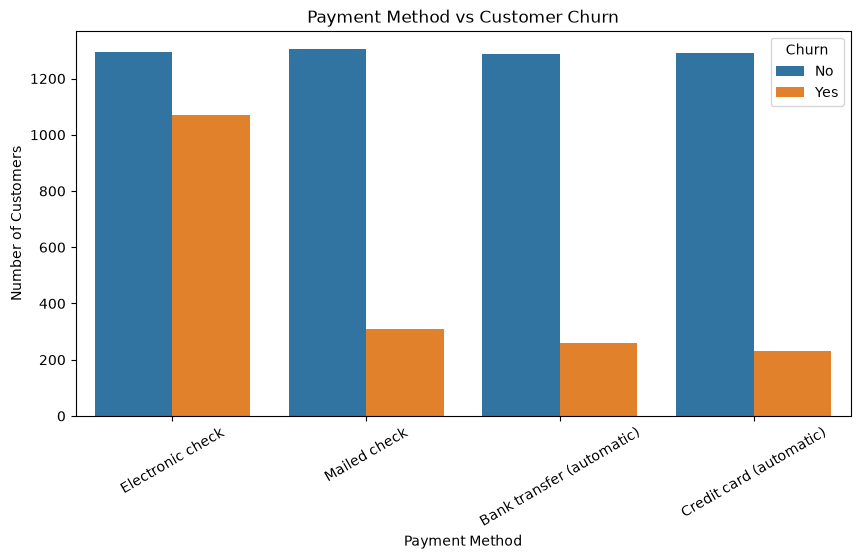

In [150]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x='PaymentMethod',
    hue='Churn'
)

plt.title('Payment Method vs Customer Churn')

plt.xlabel('Payment Method')

plt.ylabel('Number of Customers')

plt.xticks(rotation=30)

plt.show()

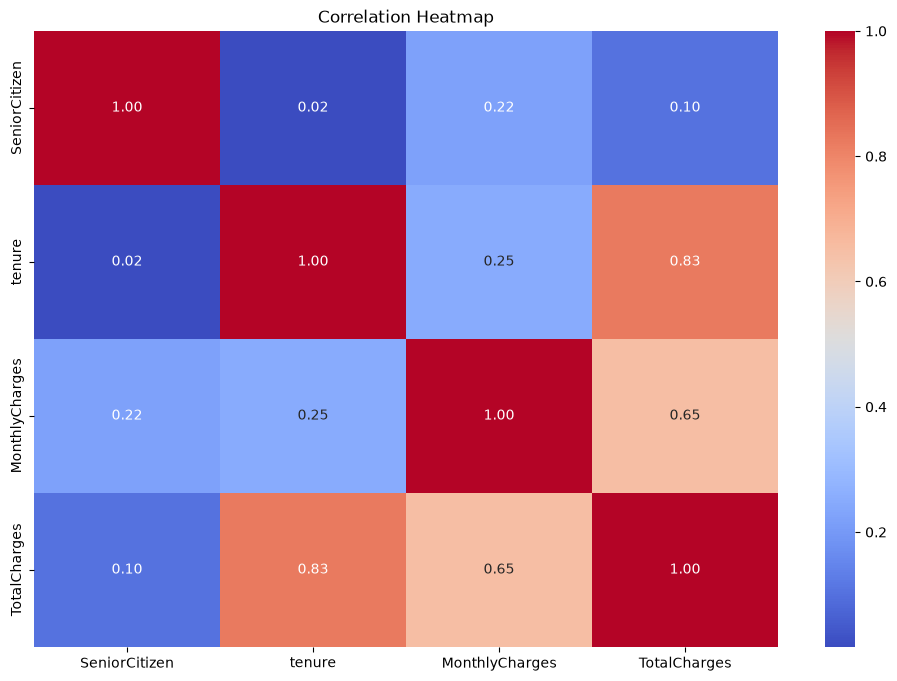

In [151]:
numerical_df = df.select_dtypes(
    include=np.number
)

correlation = numerical_df.corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')

plt.show()

## EDA Findings

1. Month-to-month contract customers show higher churn rates.

2. Customers with shorter tenure appear more likely to leave.

3. Monthly charges may be associated with customer churn.

4. Different internet service categories show different churn patterns.

5. The dataset contains an imbalance between customers who
   stayed and customers who left.

These observations will guide feature engineering and
machine learning model development.

In [152]:
service_columns = [
    'OnlineSecurity',
    'OnlineBackup',
    'DeviceProtection',
    'TechSupport',
    'StreamingTV',
    'StreamingMovies'
]

In [153]:
df['ServiceCount'] = (
    df[service_columns] == 'Yes'
).sum(axis=1)

In [154]:
df['TenureGroup'] = pd.cut(
    df['tenure'],
    bins=[-1, 12, 24, 48, 72],
    labels=[
        'New',
        'Medium',
        'Long',
        'Loyal'
    ]
)

In [155]:
df['TotalChargesPerTenure'] = (
    df['TotalCharges'] /
    df['tenure'].replace(0, np.nan)
)

In [156]:
df['NewCustomer'] = (
    df['tenure'] <= 6
).astype(int)

In [157]:
df[
    [
        'tenure',
        'ServiceCount',
        'TenureGroup',
        'TotalChargesPerTenure',
        'NewCustomer'
    ]
].head(10)

,tenure,ServiceCount,TenureGroup,TotalChargesPerTenure,NewCustomer
0,1,1,New,29.850000,1
1,34,2,Long,55.573529,0
2,2,2,New,54.075000,1
3,45,3,Long,40.905556,0
4,2,0,New,75.825000,1
5,8,3,New,102.562500,0
6,22,2,Medium,88.609091,0
7,10,1,New,30.190000,0
8,28,4,Long,108.787500,0
9,62,2,Loyal,56.257258,0


In [158]:
X = df.drop(
    columns=['Churn', 'customerID']
)

y = df['Churn'].map({
    'No': 0,
    'Yes': 1
})

In [159]:
from sklearn.model_selection import train_test_split

In [160]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [161]:
print("Training features:", X_train.shape)

print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)

print("Testing target:", y_test.shape)

Training features: (5634, 23)
Testing features: (1409, 23)
Training target: (5634,)
Testing target: (1409,)


In [162]:
from sklearn.compose import ColumnTransformer

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

from sklearn.impute import SimpleImputer

from sklearn.pipeline import Pipeline

In [163]:
numerical_columns = X_train.select_dtypes(
    include=np.number
).columns.tolist()

In [164]:
categorical_columns = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

In [165]:
print("Numerical Columns:")

print(numerical_columns)

print("\nCategorical Columns:")

print(categorical_columns)

Numerical Columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'ServiceCount', 'TotalChargesPerTenure', 'NewCustomer']

Categorical Columns:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TenureGroup']


In [166]:
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(
        strategy='median'
    )),

    ('scaler', StandardScaler())
])

In [167]:
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(
        strategy='most_frequent'
    )),

    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
    ))
])

In [168]:
preprocessor = ColumnTransformer([
    (
        'num',
        numeric_pipeline,
        numerical_columns
    ),

    (
        'cat',
        categorical_pipeline,
        categorical_columns
    )
])

In [169]:
from sklearn.linear_model import LogisticRegression

In [170]:
logistic_model = Pipeline([
    ('preprocessor', preprocessor),

    ('classifier', LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ))
])

In [171]:
logistic_model.fit(
    X_train,
    y_train
)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [172]:
logistic_predictions = logistic_model.predict(
    X_test
)

In [173]:
logistic_probabilities = (
    logistic_model.predict_proba(X_test)[:, 1]
)

In [174]:
from sklearn.ensemble import RandomForestClassifier

In [175]:
rf_model = Pipeline([
    ('preprocessor', preprocessor),

    ('classifier', RandomForestClassifier(
        n_estimators=200,
        max_depth=8,
        min_samples_split=5,
        min_samples_leaf=2,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

In [176]:
rf_model.fit(
    X_train,
    y_train
)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [177]:
rf_predictions = rf_model.predict(
    X_test
)

In [178]:
rf_probabilities = (
    rf_model.predict_proba(X_test)[:, 1]
)

In [179]:
from xgboost import XGBClassifier

In [180]:
negative_count = (
    y_train == 0
).sum()

positive_count = (
    y_train == 1
).sum()

scale_weight = (
    negative_count / positive_count
)

print(scale_weight)

2.768561872909699


In [181]:
xgb_model = Pipeline([
    ('preprocessor', preprocessor),

    ('classifier', XGBClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_weight,
        eval_metric='logloss',
        random_state=42,
        n_jobs=-1
    ))
])

In [182]:
xgb_model.fit(
    X_train,
    y_train
)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [183]:
xgb_predictions = xgb_model.predict(
    X_test
)

In [184]:
xgb_probabilities = (
    xgb_model.predict_proba(X_test)[:, 1]
)

In [185]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

In [186]:
print("LOGISTIC REGRESSION")

print(
    "Accuracy:",
    accuracy_score(y_test, logistic_predictions)
)

print(
    "Precision:",
    precision_score(y_test, logistic_predictions)
)

print(
    "Recall:",
    recall_score(y_test, logistic_predictions)
)

print(
    "F1 Score:",
    f1_score(y_test, logistic_predictions)
)

print(
    "ROC-AUC:",
    roc_auc_score(y_test, logistic_probabilities)
)

LOGISTIC REGRESSION
Accuracy: 0.7395315826827538
Precision: 0.5059021922428331
Recall: 0.8021390374331551
F1 Score: 0.6204756980351603
ROC-AUC: 0.8448862021752046


In [187]:
print("RANDOM FOREST")

print(
    "Accuracy:",
    accuracy_score(y_test, rf_predictions)
)

print(
    "Precision:",
    precision_score(y_test, rf_predictions)
)

print(
    "Recall:",
    recall_score(y_test, rf_predictions)
)

print(
    "F1 Score:",
    f1_score(y_test, rf_predictions)
)

print(
    "ROC-AUC:",
    roc_auc_score(y_test, rf_probabilities)
)

RANDOM FOREST
Accuracy: 0.7679205110007097
Precision: 0.5445920303605313
Recall: 0.767379679144385
F1 Score: 0.6370699223085461
ROC-AUC: 0.8417241468392364


In [188]:
print("XGBOOST")

print(
    "Accuracy:",
    accuracy_score(y_test, xgb_predictions)
)

print(
    "Precision:",
    precision_score(y_test, xgb_predictions)
)

print(
    "Recall:",
    recall_score(y_test, xgb_predictions)
)

print(
    "F1 Score:",
    f1_score(y_test, xgb_predictions)
)

print(
    "ROC-AUC:",
    roc_auc_score(y_test, xgb_probabilities)
)

XGBOOST
Accuracy: 0.7579843860894251
Precision: 0.5295169946332737
Recall: 0.7914438502673797
F1 Score: 0.6345123258306538
ROC-AUC: 0.8447570332480818


In [189]:
results = pd.DataFrame({

    'Model': [
        'Logistic Regression',
        'Random Forest',
        'XGBoost'
    ],

    'Accuracy': [
        accuracy_score(y_test, logistic_predictions),
        accuracy_score(y_test, rf_predictions),
        accuracy_score(y_test, xgb_predictions)
    ],

    'Precision': [
        precision_score(y_test, logistic_predictions),
        precision_score(y_test, rf_predictions),
        precision_score(y_test, xgb_predictions)
    ],

    'Recall': [
        recall_score(y_test, logistic_predictions),
        recall_score(y_test, rf_predictions),
        recall_score(y_test, xgb_predictions)
    ],

    'F1 Score': [
        f1_score(y_test, logistic_predictions),
        f1_score(y_test, rf_predictions),
        f1_score(y_test, xgb_predictions)
    ],

    'ROC-AUC': [
        roc_auc_score(y_test, logistic_probabilities),
        roc_auc_score(y_test, rf_probabilities),
        roc_auc_score(y_test, xgb_probabilities)
    ]

})

results

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.739532,0.505902,0.802139,0.620476,0.844886
1,Random Forest,0.767921,0.544592,0.767380,0.637070,0.841724
2,XGBoost,0.757984,0.529517,0.791444,0.634512,0.844757


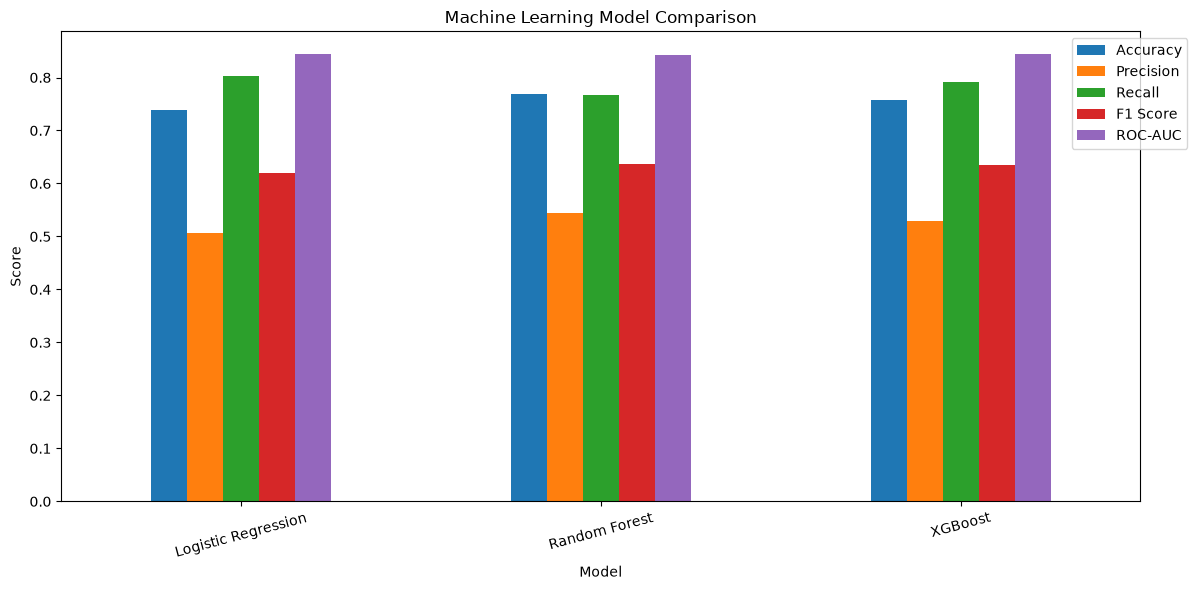

In [190]:
results.set_index('Model')[
    ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC']
].plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Machine Learning Model Comparison')

plt.ylabel('Score')

plt.xticks(rotation=15)

plt.legend(
    bbox_to_anchor=(1.05, 1)
)

plt.tight_layout()

plt.show()

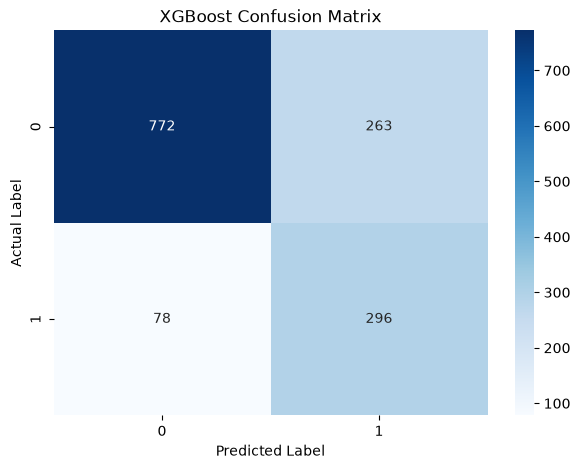

In [191]:
cm = confusion_matrix(
    y_test,
    xgb_predictions
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title('XGBoost Confusion Matrix')

plt.xlabel('Predicted Label')

plt.ylabel('Actual Label')

plt.show()

In [192]:
from sklearn.metrics import roc_curve, auc

In [193]:
fpr, tpr, thresholds = roc_curve(
    y_test,
    xgb_probabilities
)

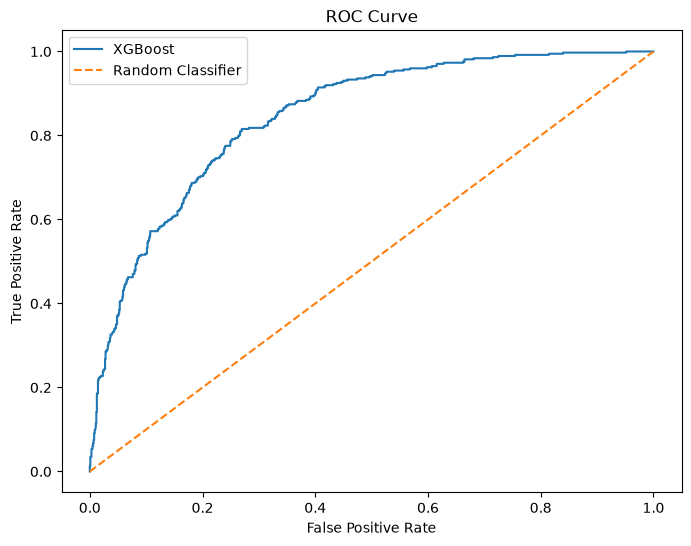

In [194]:
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label='XGBoost'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel('False Positive Rate')

plt.ylabel('True Positive Rate')

plt.title('ROC Curve')

plt.legend()

plt.show()

In [195]:
from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_score
)

In [196]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [197]:
logistic_cv = cross_val_score(
    logistic_model,
    X_train,
    y_train,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1
)

print("Fold Scores:", logistic_cv)

print("Mean ROC-AUC:", logistic_cv.mean())

Fold Scores: [0.84432811 0.83047154 0.84280129 0.85903293 0.85885236]
Mean ROC-AUC: 0.8470972459374295


In [198]:
rf_cv = cross_val_score(
    rf_model,
    X_train,
    y_train,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1
)

print("Random Forest CV Scores:", rf_cv)

print("Mean ROC-AUC:", rf_cv.mean())

Random Forest CV Scores: [0.84372627 0.83207107 0.84495016 0.85738896 0.85660383]
Mean ROC-AUC: 0.8469480591880776


In [199]:
xgb_cv = cross_val_score(
    xgb_model,
    X_train,
    y_train,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1
)

print("XGBoost CV Scores:", xgb_cv)

print("Mean ROC-AUC:", xgb_cv.mean())

XGBoost CV Scores: [0.84142189 0.83403414 0.84521069 0.85957418 0.8564906 ]
Mean ROC-AUC: 0.8473462998151957


In [200]:
n_estimators=200
max_depth=8

In [201]:
from sklearn.model_selection import GridSearchCV

In [202]:
param_grid = {

    'classifier__n_estimators': [
        100,
        200
    ],

    'classifier__max_depth': [
        4,
        6,
        8
    ],

    'classifier__min_samples_split': [
        2,
        5
    ]

}

In [203]:
rf_grid = GridSearchCV(
    estimator=rf_model,
    param_grid=param_grid,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1
)

In [204]:
rf_grid.fit(
    X_train,
    y_train
)

Fitting 5 folds for each of 12 candidates, totalling 60 fits


,estimator,Pipeline(step...m_state=42))])
,param_grid,"{'classifier__max_depth': [4, 6, ...], 'classifier__min_samples_split': [2, 5], 'classifier__n_estimators': [100, 200]}"
,scoring,'roc_auc'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [205]:
print(rf_grid.best_params_)

{'classifier__max_depth': 8, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 100}


In [206]:
print(rf_grid.best_score_)

0.8476789652446763


In [207]:
best_rf_model = rf_grid.best_estimator_

In [208]:
xgb_param_grid = {

    'classifier__n_estimators': [
        100,
        200
    ],

    'classifier__max_depth': [
        3,
        4,
        5
    ],

    'classifier__learning_rate': [
        0.01,
        0.05,
        0.1
    ]

}

In [209]:
xgb_grid = GridSearchCV(
    estimator=xgb_model,
    param_grid=xgb_param_grid,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1
)

In [210]:
xgb_grid.fit(
    X_train,
    y_train
)

Fitting 5 folds for each of 18 candidates, totalling 90 fits


,estimator,"Pipeline(step...=None, ...))])"
,param_grid,"{'classifier__learning_rate': [0.01, 0.05, ...], 'classifier__max_depth': [3, 4, ...], 'classifier__n_estimators': [100, 200]}"
,scoring,'roc_auc'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [211]:
print(xgb_grid.best_params_)

{'classifier__learning_rate': 0.05, 'classifier__max_depth': 3, 'classifier__n_estimators': 100}


In [212]:
best_xgb_model = xgb_grid.best_estimator_

In [213]:
from sklearn.model_selection import cross_val_predict

validation_probabilities = cross_val_predict(
    best_xgb_model,
    X_train,
    y_train,
    cv=cv,
    method='predict_proba',
    n_jobs=-1
)[:, 1]

In [214]:
from sklearn.metrics import precision_score, recall_score

for threshold in [0.30, 0.40, 0.50, 0.60]:

    predictions = (
        validation_probabilities >= threshold
    ).astype(int)

    precision = precision_score(
        y_train,
        predictions
    )

    recall = recall_score(
        y_train,
        predictions
    )

    print(
        threshold,
        "Precision:", precision,
        "Recall:", recall
    )

0.3 Precision: 0.42768079800498754 Recall: 0.9177257525083612
0.4 Precision: 0.4722926475914524 Recall: 0.8722408026755852
0.5 Precision: 0.5189655172413793 Recall: 0.8053511705685619
0.6 Precision: 0.575083426028921 Recall: 0.691638795986622


In [215]:
import shap

In [216]:
X_test_transformed = (
    best_xgb_model
    .named_steps['preprocessor']
    .transform(X_test)
)

In [217]:
feature_names = (
    best_xgb_model
    .named_steps['preprocessor']
    .get_feature_names_out()
)

In [218]:
explainer = shap.TreeExplainer(
    best_xgb_model
    .named_steps['classifier']
)

In [219]:
shap_values = explainer(
    X_test_transformed[:200]
)

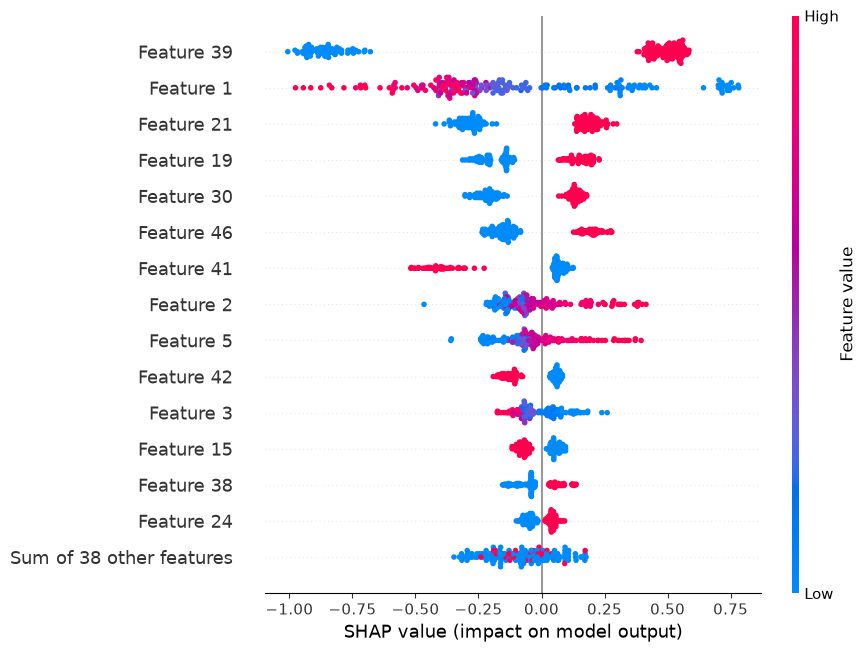

In [220]:
shap.plots.beeswarm(
    shap_values,
    max_display=15
)

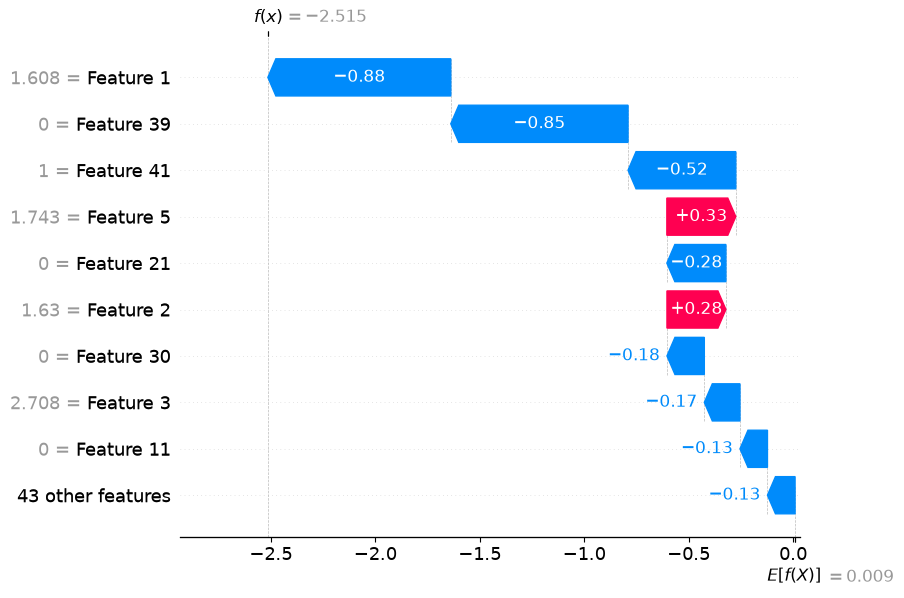

In [221]:
shap.plots.waterfall(
    shap_values[0]
)

In [222]:
import joblib

In [223]:
import os

os.makedirs('../models', exist_ok=True)

print("Models folder created successfully!")

Models folder created successfully!


In [224]:
import joblib

joblib.dump(
    best_xgb_model,
    '../models/best_model.pkl'
)

['../models/best_model.pkl']

In [225]:
best_threshold = 0.50

joblib.dump(
    best_threshold,
    '../models/best_threshold.pkl'
)

['../models/best_threshold.pkl']

In [226]:
loaded_model = joblib.load(
    '../models/best_model.pkl'
)

In [227]:
loaded_model.predict(X_test)

array([0, 1, 0, ..., 0, 0, 0], shape=(1409,))

In [228]:
import streamlit as st

import pandas as pd

import numpy as np

import joblib

In [229]:
st.set_page_config(
    page_title="ConnectTel Churn Prediction",
    page_icon="📊",
    layout="wide"
)

2026-11-21 17:27:48.705 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


In [230]:
st.title(
    "ConnectTel Customer Churn Prediction"
)

st.write(
    "Predict customer churn risk using machine learning."
)

2026-11-21 17:27:48.761 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-21 17:27:48.764 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-21 17:27:48.777 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-21 17:27:48.790 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-21 17:27:48.791 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-21 17:27:48.793 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


In [231]:
@st.cache_resource
def load_model():

    return joblib.load(
        '../models/best_model.pkl'
    )

model = load_model()

In [232]:
threshold = joblib.load(
    '../models/best_threshold.pkl'
)

In [233]:
st.header("Customer Information")

with st.form("customer_form"):

    tenure = st.number_input(
        "Customer Tenure (Months)",
        min_value=0,
        max_value=72,
        value=12
    )

    monthly_charges = st.number_input(
        "Monthly Charges",
        min_value=0.0,
        value=70.0
    )

    contract = st.selectbox(
        "Contract Type",
        [
            "Month-to-month",
            "One year",
            "Two year"
        ]
    )

    internet_service = st.selectbox(
        "Internet Service",
        [
            "DSL",
            "Fiber optic",
            "No"
        ]
    )

    submitted = st.form_submit_button(
        "Predict Churn"
    )

2026-11-21 17:27:48.910 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-21 17:27:48.914 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-21 17:27:48.916 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-21 17:27:48.921 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-21 17:27:48.927 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-21 17:27:48.931 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-21 17:27:48.937 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-21 17:27:48.941 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bar

In [234]:
with st.form("complete_customer_form"):

    gender = st.selectbox(
        "Gender",
        ["Male", "Female"]
    )

    senior_citizen = st.selectbox(
        "Senior Citizen",
        [0, 1]
    )

    partner = st.selectbox(
        "Partner",
        ["Yes", "No"]
    )

    dependents = st.selectbox(
        "Dependents",
        ["Yes", "No"]
    )

    tenure = st.number_input(
        "Tenure",
        min_value=0,
        max_value=72,
        value=12
    )

    phone_service = st.selectbox(
        "Phone Service",
        ["Yes", "No"]
    )

    multiple_lines = st.selectbox(
        "Multiple Lines",
        ["Yes", "No", "No phone service"]
    )

    internet_service = st.selectbox(
        "Internet Service",
        ["DSL", "Fiber optic", "No"]
    )

    online_security = st.selectbox(
        "Online Security",
        ["Yes", "No", "No internet service"]
    )

    online_backup = st.selectbox(
        "Online Backup",
        ["Yes", "No", "No internet service"]
    )

    device_protection = st.selectbox(
        "Device Protection",
        ["Yes", "No", "No internet service"]
    )

    tech_support = st.selectbox(
        "Tech Support",
        ["Yes", "No", "No internet service"]
    )

    streaming_tv = st.selectbox(
        "Streaming TV",
        ["Yes", "No", "No internet service"]
    )

    streaming_movies = st.selectbox(
        "Streaming Movies",
        ["Yes", "No", "No internet service"]
    )

    contract = st.selectbox(
        "Contract",
        ["Month-to-month", "One year", "Two year"]
    )

    paperless_billing = st.selectbox(
        "Paperless Billing",
        ["Yes", "No"]
    )

    payment_method = st.selectbox(
        "Payment Method",
        [
            "Electronic check",
            "Mailed check",
            "Bank transfer (automatic)",
            "Credit card (automatic)"
        ]
    )

    monthly_charges = st.number_input(
        "Monthly Charges",
        min_value=0.0,
        value=70.0
    )

    total_charges = st.number_input(
        "Total Charges",
        min_value=0.0,
        value=840.0
    )

    submitted = st.form_submit_button(
        "Predict Churn"
    )

2026-11-21 17:27:49.054 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-21 17:27:49.056 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-21 17:27:49.058 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-21 17:27:49.060 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-21 17:27:49.062 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-21 17:27:49.067 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-21 17:27:49.068 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-21 17:27:49.070 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bar

In [235]:
service_count = sum([
    online_security == "Yes",
    online_backup == "Yes",
    device_protection == "Yes",
    tech_support == "Yes",
    streaming_tv == "Yes",
    streaming_movies == "Yes"
])

tenure_group = pd.cut(
    [tenure],
    bins=[-1, 12, 24, 48, 72],
    labels=['New', 'Medium', 'Long', 'Loyal']
)[0]

total_charges_per_tenure = (
    total_charges / tenure if tenure > 0 else np.nan
)

new_customer = int(tenure <= 6)

In [236]:
customer_data = pd.DataFrame([{

    'gender': gender,
    'SeniorCitizen': senior_citizen,
    'Partner': partner,
    'Dependents': dependents,
    'tenure': tenure,
    'PhoneService': phone_service,
    'MultipleLines': multiple_lines,
    'InternetService': internet_service,
    'OnlineSecurity': online_security,
    'OnlineBackup': online_backup,
    'DeviceProtection': device_protection,
    'TechSupport': tech_support,
    'StreamingTV': streaming_tv,
    'StreamingMovies': streaming_movies,
    'Contract': contract,
    'PaperlessBilling': paperless_billing,
    'PaymentMethod': payment_method,
    'MonthlyCharges': monthly_charges,
    'TotalCharges': total_charges,
    'ServiceCount': service_count,
    'TenureGroup': tenure_group,
    'TotalChargesPerTenure': total_charges_per_tenure,
    'NewCustomer': new_customer

}])

print(customer_data)

  gender  SeniorCitizen Partner Dependents  tenure PhoneService MultipleLines  \
0   Male              0     Yes        Yes      12          Yes           Yes   

  InternetService OnlineSecurity OnlineBackup  ... StreamingMovies  \
0             DSL            Yes          Yes  ...             Yes   

         Contract PaperlessBilling     PaymentMethod MonthlyCharges  \
0  Month-to-month              Yes  Electronic check           70.0   

  TotalCharges ServiceCount  TenureGroup  TotalChargesPerTenure  NewCustomer  
0        840.0            6          New                   70.0            0  

[1 rows x 23 columns]


In [237]:
    churn_probability = (
        model.predict_proba(customer_data)[0][1]
    )

    churn_prediction = int(
        churn_probability >= threshold
    )

In [238]:
    st.subheader("Prediction Result")

    st.metric(
        "Churn Probability",
        f"{churn_probability * 100:.2f}%"
    )

    if churn_prediction == 1:

        st.error(
            "Customer is classified as HIGHER CHURN RISK"
        )

    else:

        st.success(
            "Customer is classified as LOWER CHURN RISK"
        )

2026-11-21 17:27:49.562 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-21 17:27:49.565 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-21 17:27:49.567 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-21 17:27:49.570 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-21 17:27:49.572 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-21 17:27:49.575 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-21 17:27:49.578 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-21 17:27:49.581 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bar